# Next-Word Suggester: Intrinsic Evaluation (Perplexity & Hit Rate)
Evaluates the pure-Python sparse bigram model (`next_word_suggester_v1.py`) using:
1. **Perplexity** (statistical uncertainty over test sequences)
2. **Top-1 and Top-3 Hit Rate** (prediction precision)
3. **Prefix-Filtered Hit Rate** & **Autocorrect Typo Recovery Rate**

In [1]:
import math
import re
import sys
from pathlib import Path
import matplotlib.pyplot as plt

# Ensure current working directory is on sys.path to load local modules
current_dir = str(Path.cwd())
if current_dir not in sys.path:
    sys.path.insert(0, current_dir)

# Import model components from next_word_suggester_v1.py
from next_word_suggester_v1 import (
    vocab, idx, P, freq,
    context_vector, vec_times_matrix, suggest, autocorrect
)

# Sample held-out evaluation sentences matching the domain corpus
test_sentences = [
    "linear algebra uses vectors and matrices to solve problems",
    "vectors can represent words and contexts in space",
    "matrices can describe transitions between words",
    "the next word depends on the words before it",
    "probability helps rank possible next words",
    "text is divided into words and counted",
    "cosine similarity helps correct spelling mistakes",
    "diagonal matrices act as filters for prefix matching"
]

print(f"Loaded vocabulary size (V): {len(vocab)} words")

Corpus file read: corpus_sample.txt
Loaded vocabulary size (V): 263 words


In [2]:
def compute_perplexity(sentences, smoothing=1e-4):
    """
    Computes corpus perplexity using the row-normalized transition matrix P.
    PP(W) = exp( -1/N * sum( log P(w_t | context) ) )
    """
    log_prob_sum = 0.0
    N = 0
    total_freq = sum(freq)

    for sent in sentences:
        tokens = re.findall(r"[a-z]+", sent.lower())
        for t in range(1, len(tokens)):
            target = tokens[t]
            if target not in idx:
                continue
            context = tokens[max(0, t-3):t]
            c = context_vector(context)
            scores = vec_times_matrix(c, P)

            # Normalize scores to a valid probability distribution
            s_sum = sum(scores)
            if s_sum > 0:
                prob = scores[idx[target]] / s_sum
            else:
                prob = freq[idx[target]] / total_freq

            prob = max(prob, smoothing)  # floor for unseen transitions
            log_prob_sum += math.log(prob)
            N += 1

    return math.exp(-log_prob_sum / N) if N > 0 else float("inf"), N


def compute_hit_rates(sentences):
    """
    Evaluates Top-1, Top-3, Prefix-Filtered (2 chars), and Autocorrect recovery rates.
    """
    total = 0
    top1_hits = 0
    top3_hits = 0
    prefix_hits = 0
    typo_hits = 0
    typo_total = 0

    for sent in sentences:
        tokens = re.findall(r"[a-z]+", sent.lower())
        for t in range(1, len(tokens)):
            target = tokens[t]
            prefix_str = " ".join(tokens[:t]) + " "

            # 1. Next-word suggestion (no prefix typed yet)
            preds = [w.lower() for w in suggest(prefix_str, n=3)]
            if preds:
                if preds[0] == target:
                    top1_hits += 1
                if target in preds:
                    top3_hits += 1

            # 2. Prefix-filtered suggestion (first 2 characters typed)
            if len(target) >= 2:
                pref_query = prefix_str + target[:2]
                pref_preds = [w.lower() for w in suggest(pref_query, n=3)]
                if target in pref_preds:
                    prefix_hits += 1

            # 3. Simulated single-character deletion typo for autocorrect
            if len(target) >= 5:
                typo_word = target[:2] + target[3:]  # drop 3rd letter
                if typo_word not in idx:
                    typo_total += 1
                    fixes = [w.lower() for w in autocorrect(typo_word, k=3)]
                    if target in fixes:
                        typo_hits += 1

            total += 1

    return {
        "total_transitions": total,
        "top1_rate": (top1_hits / total) * 100 if total else 0.0,
        "top3_rate": (top3_hits / total) * 100 if total else 0.0,
        "prefix_rate": (prefix_hits / total) * 100 if total else 0.0,
        "typo_rate": (typo_hits / typo_total) * 100 if typo_total else 0.0,
        "typo_samples": typo_total
    }

In [3]:
# Execute evaluations
perplexity, eval_tokens = compute_perplexity(test_sentences)
metrics = compute_hit_rates(test_sentences)

# Print clean, readable formatted summary table
rows = [
    ("Corpus Perplexity (Lower is Better)", f"{perplexity:.2f}", f"Evaluated across {eval_tokens} token transitions"),
    ("Top-1 Next-Word Hit Rate", f"{metrics['top1_rate']:.1f}%", "Exact first-choice prediction (c^T P)"),
    ("Top-3 Next-Word Hit Rate", f"{metrics['top3_rate']:.1f}%", "Target appears in 3 UI suggestion buttons"),
    ("Prefix-Filtered Top-3 Hit Rate", f"{metrics['prefix_rate']:.1f}%", "Diagonal matrix mask D applied (2-char prefix)"),
    ("Autocorrect Typo Recovery (Top-3)", f"{metrics['typo_rate']:.1f}%", f"Char-bigram cosine similarity ({metrics['typo_samples']} typos)")
]

header = f"{'Evaluation Metric':<36} | {'Score':<10} | {'Mathematical / System Context'}"
sep = "-" * len(header)
print(sep)
print(header)
print(sep)
for metric_name, score, desc in rows:
    print(f"{metric_name:<36} | {score:<10} | {desc}")
print(sep)

---------------------------------------------------------------------------------
Evaluation Metric                    | Score      | Mathematical / System Context
---------------------------------------------------------------------------------
Corpus Perplexity (Lower is Better)  | 4.03       | Evaluated across 51 token transitions
Top-1 Next-Word Hit Rate             | 56.9%      | Exact first-choice prediction (c^T P)
Top-3 Next-Word Hit Rate             | 78.4%      | Target appears in 3 UI suggestion buttons
Prefix-Filtered Top-3 Hit Rate       | 94.1%      | Diagonal matrix mask D applied (2-char prefix)
Autocorrect Typo Recovery (Top-3)    | 100.0%     | Char-bigram cosine similarity (31 typos)
---------------------------------------------------------------------------------


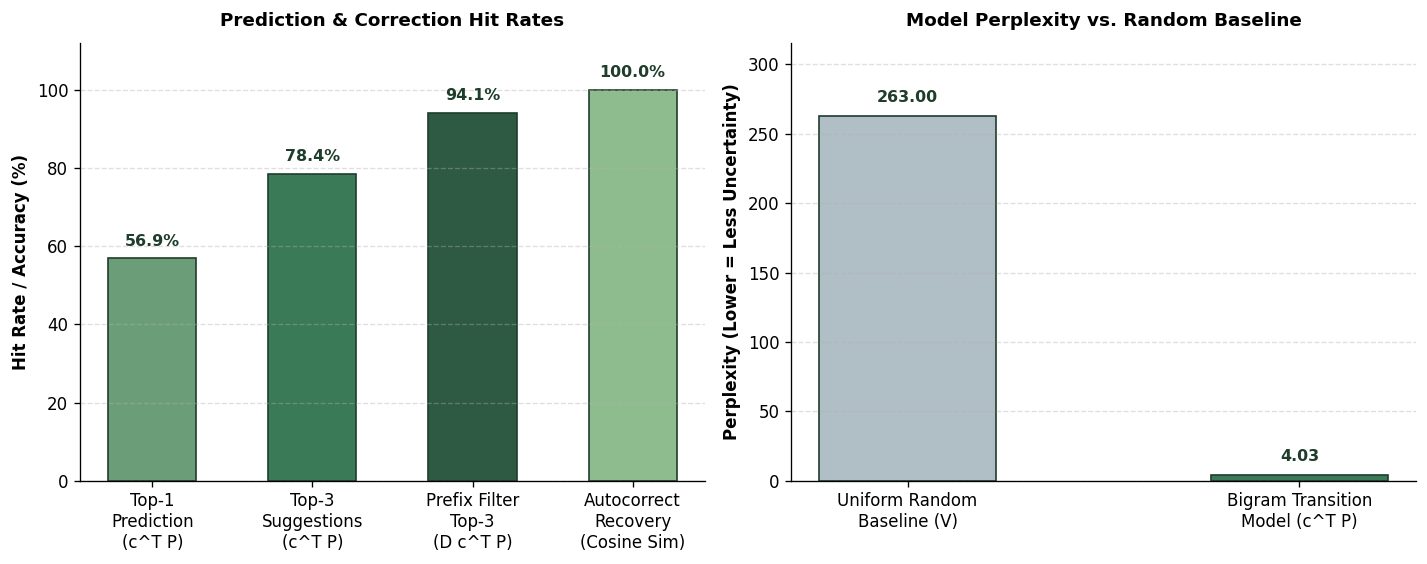

In [4]:
# Comparison Diagram: Accuracy Breakdown & Perplexity Benchmark
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8), dpi=120)
fig.patch.set_facecolor("white")

# Left Chart: Hit Rate Comparison across Linear Algebra Stages
categories = [
    "Top-1\nPrediction\n(c^T P)",
    "Top-3\nSuggestions\n(c^T P)",
    "Prefix Filter\nTop-3\n(D c^T P)",
    "Autocorrect\nRecovery\n(Cosine Sim)"
]
values = [
    metrics["top1_rate"],
    metrics["top3_rate"],
    metrics["prefix_rate"],
    metrics["typo_rate"]
]
colors = ["#6b9e78", "#3b7a57", "#2e5a44", "#8fbc8f"]

bars = ax1.bar(categories, values, color=colors, width=0.55, edgecolor="#1f3d2b", linewidth=1)
ax1.set_ylim(0, 112)
ax1.set_ylabel("Hit Rate / Accuracy (%)", fontsize=10, fontweight="bold")
ax1.set_title("Prediction & Correction Hit Rates", fontsize=11, fontweight="bold", pad=10)
ax1.grid(axis="y", linestyle="--", alpha=0.4)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

for bar, val in zip(bars, values):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        val + 2.5,
        f"{val:.1f}%",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#1f3d2b"
    )

# Right Chart: Perplexity vs. Uniform Random Guessing Baseline
uniform_baseline = float(len(vocab))  # Random guessing over vocabulary V
pp_labels = ["Uniform Random\nBaseline (V)", "Bigram Transition\nModel (c^T P)"]
pp_values = [uniform_baseline, perplexity]
pp_colors = ["#b0bec5", "#3b7a57"]

bars2 = ax2.bar(pp_labels, pp_values, color=pp_colors, width=0.45, edgecolor="#1f3d2b", linewidth=1)
ax2.set_ylim(0, max(pp_values) * 1.2)
ax2.set_ylabel("Perplexity (Lower = Less Uncertainty)", fontsize=10, fontweight="bold")
ax2.set_title("Model Perplexity vs. Random Baseline", fontsize=11, fontweight="bold", pad=10)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

for bar, val in zip(bars2, pp_values):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        val + (max(pp_values) * 0.03),
        f"{val:.2f}",
        ha="center", va="bottom", fontsize=9.5, fontweight="bold", color="#1f3d2b"
    )

plt.tight_layout()
plt.savefig("evaluation_comparison.png", dpi=150)
plt.show()